In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
initial_state = .5
upper_threshold = .8
lower_threshold = .2

In [3]:
log_odds = lambda x: np.log(x / (1 - x))

In [4]:
# build toy example with set number of observations and influence on probability
# seed = np.random.seed(52)

In [5]:
# use a beta distribution
# alpha = mean * ((mean(mean - 1)/variance) - 1)
# beta = (1 - mean) * ((mean * (mean - 1) / variance) - 1)
mean = .5
variance = .05
alpha = mean * ((mean * (1 - mean) / variance) - 1)
beta = (1 - mean) * ((mean * (1 - mean) / variance) - 1)
observations = 100
log_to_probabilities = lambda x: 1 / (1 + np.exp(-x))

In [6]:
number_of_simulations = 50

simulations = np.zeros((number_of_simulations, observations + 1))
all_evidence = np.random.beta(alpha, beta, (number_of_simulations, observations))
log_evidence = log_odds(all_evidence)
cumulative_log = np.cumsum(log_evidence, axis=1)
initial_log = log_odds(initial_state) * np.ones((number_of_simulations, 1))

In [14]:
all_evidence

array([[0.52641281, 0.16260567, 0.88877166, ..., 0.55247589, 0.42765268,
        0.17432214],
       [0.41444734, 0.73224499, 0.79633332, ..., 0.44449176, 0.61731898,
        0.28182783],
       [0.35089618, 0.73713119, 0.16109474, ..., 0.08494914, 0.42712561,
        0.4508997 ],
       ...,
       [0.64974714, 0.40540444, 0.79613762, ..., 0.38652916, 0.63994298,
        0.34529478],
       [0.19605416, 0.71026847, 0.19802385, ..., 0.47832542, 0.43712723,
        0.77004502],
       [0.38035372, 0.33817589, 0.4258807 , ..., 0.80748971, 0.53873821,
        0.85631248]], shape=(50, 100))

In [7]:
initial_log

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [8]:
cumulative_log.shape

(50, 100)

In [9]:
simulations = np.concatenate([initial_log, cumulative_log + initial_log], axis=1)

In [10]:
simulations

array([[ 0.        ,  0.10574967, -1.53321735, ..., -1.02457928,
        -1.31601393, -2.87131366],
       [ 0.        , -0.34561019,  0.66043254, ...,  0.34115725,
         0.81934133, -0.11607166],
       [ 0.        , -0.61510226,  0.41600853, ..., -5.97489958,
        -6.26848793, -6.46552412],
       ...,
       [ 0.        ,  0.61792791,  0.23493165, ...,  1.05424267,
         1.62935934,  0.98957273],
       [ 0.        , -1.41114094, -0.51445267, ...,  8.66415433,
         8.41132501,  9.61989043],
       [ 0.        , -0.48804713, -1.15948082, ..., -1.16002695,
        -1.00476295,  0.78023146]], shape=(50, 101))

In [11]:
simulations.shape

(50, 101)

In [12]:
simulations[0]

array([ 0.        ,  0.10574967, -1.53321735,  0.54503777,  1.0670559 ,
        0.76321233,  0.76964352, -0.13153404, -2.01672716, -3.77185359,
       -4.46723784, -2.99448834, -2.68992242, -3.34576737, -3.94987531,
       -3.18137256, -1.32439152,  0.02324136,  0.060241  ,  0.30808113,
        3.38184874,  2.23036084,  2.62523527,  2.58037022,  3.04262612,
        2.72510221,  3.80356223,  4.85719196,  4.16474041,  2.28859784,
        1.60760977,  1.46714773,  2.45236404,  2.24144862,  1.23571189,
        2.37626017,  3.53558237,  3.98040377,  4.98608583,  6.8520961 ,
        7.62761964,  5.41673643,  6.4183649 ,  6.76849748,  7.50754308,
        6.95121018,  6.45808672,  5.64754957,  5.96641632,  6.44475782,
        7.08982685,  6.25139166,  5.89133833,  5.10338612,  5.79762652,
        4.7806136 ,  5.03349684,  4.57936716,  4.89532029,  2.85770957,
        0.13776053, -0.13635578, -0.37596411,  1.0198928 ,  2.00858319,
        1.87059175,  0.91825278,  1.39277104,  1.82182581,  4.29

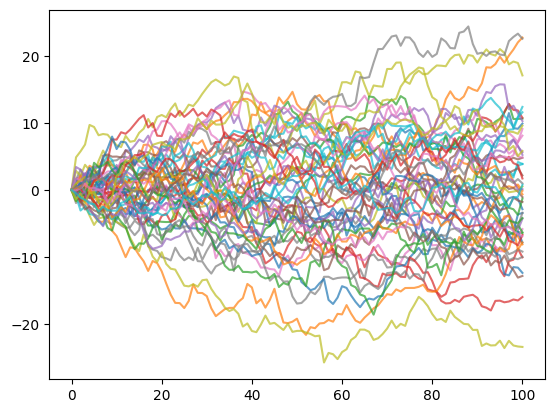

In [13]:
for sim in simulations:
    plt.plot(sim, alpha=0.7)